# 量子機械学習

Kifumi Numata, IBM Quantum (Nov 12, 2026)

Google Colab で行う場合は、次のセルの「#」を削除して実行します。

In [1]:
#%pip install qiskit[visualization] qiskit-ibm-runtime qiskit-aer scikit-learn

In [2]:
import qiskit
qiskit.__version__

'2.6.2'

### 目次:
1. データの符号化
2. 量子カーネル分類
3. 量子変分回路による分類

# 1. データの符号化
## 1.1 基底エンコーディング

基底エンコーディング(basis encoding)は、古典的な $P$ ビットの文字列を $P$ 量子ビット系の計算基底状態にエンコードします。

$\vec{x} = (5,7,0)$ をエンコードしてみましょう。すべての特徴量が 4 ビットで格納されるとします (必要以上ですが、10 進数で 1 桁の任意の整数を表すには十分です)。

5 → 2 進数 0101

7 → 2 進数 0111

0 → 2 進数 0000

これらのビット列は 4 量子ビットずつの 3 つの組に割り当てられるため、全体の 12 量子ビットの基底状態は次のようになります。

$$∣0101 0111 0000⟩$$

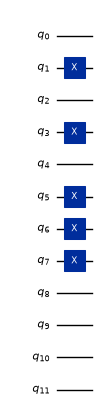

In [3]:
from qiskit import QuantumCircuit

# エンコードするデータ点
x = 5  # 2 進数: 0101
y = 7  # 2 進数: 0111
z = 0  # 2 進数: 0000

# それぞれを 4 ビットの 2 進数リストに変換
x_bits = [int(b) for b in format(x, "04b")]  # [0,1,0,1]
y_bits = [int(b) for b in format(y, "04b")]  # [0,1,1,1]
z_bits = [int(b) for b in format(z, "04b")]  # [0,0,0,0]

# すべてのビットを結合
all_bits = x_bits + y_bits + z_bits  # [0,1,0,1,0,1,1,1,0,0,0,0]

# 12 量子ビットの量子回路を初期化
qc = QuantumCircuit(12)

# ビットが 1 の位置に X ゲートを適用
for idx, bit in enumerate(all_bits):
    if bit == 1:
        qc.x(idx)

qc.draw("mpl", scale=0.5)

## 1.2 振幅エンコーディング

振幅エンコーディング(amplitude encoding)は、データを量子状態の振幅にエンコードします。
$\vec{x} = (4,8,5)$ を振幅エンコーディングでエンコードしてみましょう。まず、求めるベクトルを規格化するための定数 $\alpha$ を計算します。

$$\sum_{i=1}^N \left|x_i\right|^2 = 4^2+8^2+5^2 = 105 = \left|\alpha\right|^2 \rightarrow \alpha = \sqrt{105}$$

この定数を使い、データを計算基底の振幅の順に並べると、量子状態は次のようになります。

$$|\psi(\vec{x})\rangle = \frac{1}{\sqrt{105}}(4|00\rangle+8|01\rangle+5|10\rangle+0|11\rangle)$$

上の例では、ベクトルの要素数 $N=3$ は2のべき乗ではありません。$N$ が2のべき乗でない場合は、$2^n\geq N$ を満たす最小の $n$ を量子ビット数とし、残りの振幅はゼロで埋めます。今回は $n=2$ が最小なので、2量子ビットの状態として準備しました。

データセットをエンコードした状態を計算できれば、Qiskit の `initialize` 関数でその状態を準備できます。

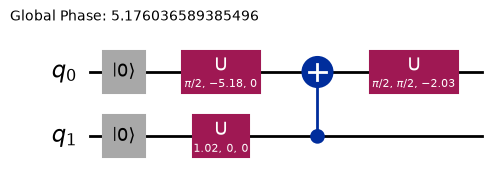

In [4]:
import math
desired_state = [
    1 / math.sqrt(105) * 4,
    1 / math.sqrt(105) * 8,
    1 / math.sqrt(105) * 5,
    1 / math.sqrt(105) * 0]

qc = QuantumCircuit(2)
qc.initialize(desired_state, [0,1])

qc.decompose(reps=5).draw(output = 'mpl')

この量子回路を測定してみましょう。データが確率振幅に反映されていることがわかります。

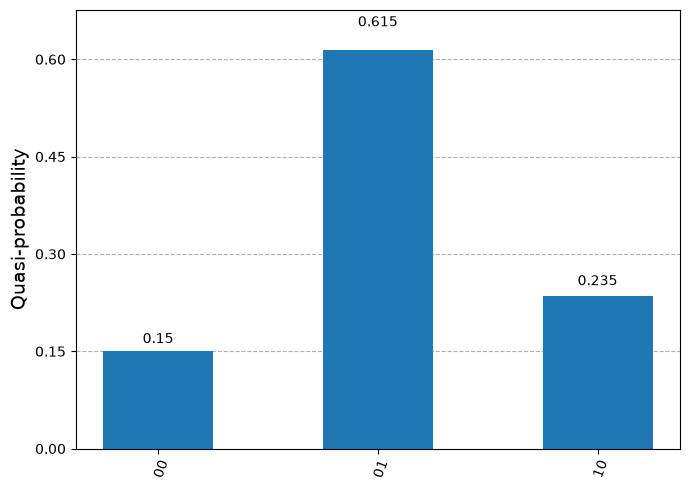

In [5]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.executor_sampler import Sampler

qc.measure_all()
backend = AerSimulator()
sampler = Sampler(backend)
job = sampler.run([qc])

counts = job.result()[0].data.meas.get_counts()

from qiskit.visualization import plot_distribution
plot_distribution(counts)   

## 1.3 角度エンコーディング

角度エンコーディング(angle encoding)は、データを $R_X$ ゲートや $R_Y$ ゲートなどの回転ゲートの角度にエンコードします。角度エンコーディングは、量子サポートベクターマシン(QSVM)や変分量子回路(VQC)など、量子特徴量マップを用いる量子機械学習アルゴリズムで重要です。

以下では、$\vec{x}= (0, \pi/4, \pi/2)$ を $R_Y$ ゲートでエンコードします。

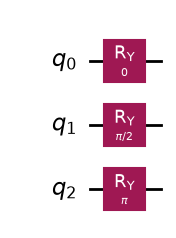

In [6]:
qc = QuantumCircuit(3)
qc.ry(0, 0)
qc.ry(2*math.pi/4, 1)
qc.ry(2*math.pi/2, 2)
qc.draw(output = 'mpl')

## 1.4 位相エンコーディング
位相エンコーディングは、上で説明した角度エンコーディングとよく似ています。量子ビットの位相角とは、$z$ 軸周りに +$x$ 軸から測った実数値の角度 $\phi$ のことです。

次の例では、まずアダマールゲートで回転させて単一の量子ビットの初期状態を準備し、次に位相ゲートで再び回転させてデータ特徴量 $\vec{x}^{(j)}_k=\frac{1}{2}\pi$ をエンコードします。

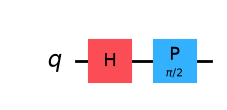

In [7]:
from math import pi
qc = QuantumCircuit(1)
qc.h(0)  # アダマールゲートが状態をブロッホ球の赤道まで回転させる
qc.p(pi / 2, 0)  # 位相ゲートが角度 pi/2 だけ回転させる
qc.draw("mpl", scale=1)

## 1.5 組み込みの特徴量マップによるエンコーディング

Qiskit の[回路ライブラリ](https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library)には、さまざまな特徴量マップが用意されています。

### Z 特徴量マップ

[`z_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.z_feature_map)(ZFM)は、角度エンコーディングを自然に拡張したシンプルな特徴量マップです。以下では、2次元のデータに対して繰り返し回数3の ZFM の回路を作成します。

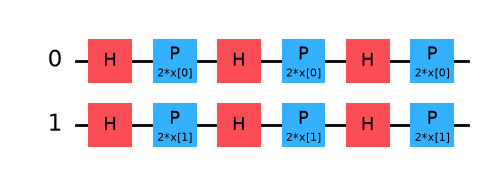

In [8]:
from qiskit.circuit.library import z_feature_map
from math import pi

zfeature_map = z_feature_map(feature_dimension=2, reps=3)
zfeature_map.draw("mpl")

`assign_parameters` を使ってパラメーターにデータを入力します。

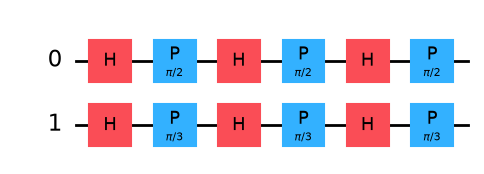

In [9]:
zfeature_map = zfeature_map.assign_parameters([(1/2)*pi/2, (1/2)*pi/3])
zfeature_map.draw("mpl")

### ZZ 特徴量マップ
[`zz_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.zz_feature_map)(ZZFM)は、ZFM に2量子ビットのエンタングリングゲート、具体的には $ZZ$ 回転ゲート $R_{ZZ}(\theta)$ を加えて拡張したものです。ZFM とは異なり、ZZFM は一般に古典コンピューターでの計算コストが高いと予想されています。

以下は4次元のデータに対するもので、エンタングルメントは線形構造(`linear`)、繰り返しは ZZFM 回路1回分です。

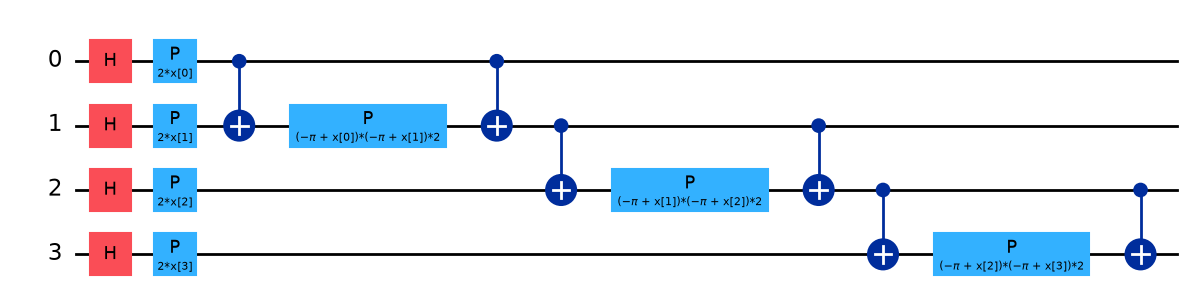

In [10]:
from qiskit.circuit.library import zz_feature_map
 
feature_dim = 4
zzfeature_map = zz_feature_map(
    feature_dimension=feature_dim, entanglement='linear', reps=1
)
zzfeature_map.draw("mpl", scale=1)

### パウリ特徴量マップ

[`pauli_feature_map`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.pauli_feature_map)(PFM)は、ZFM と ZZFM を任意のパウリゲートを使えるように一般化したものです。以下の PFM は3次元のデータに対するもので、エンタングルメントは `circular`(線形に加えて両端の量子ビットの組も結合する構造)、パウリ演算子は "Y" と "XX" です。

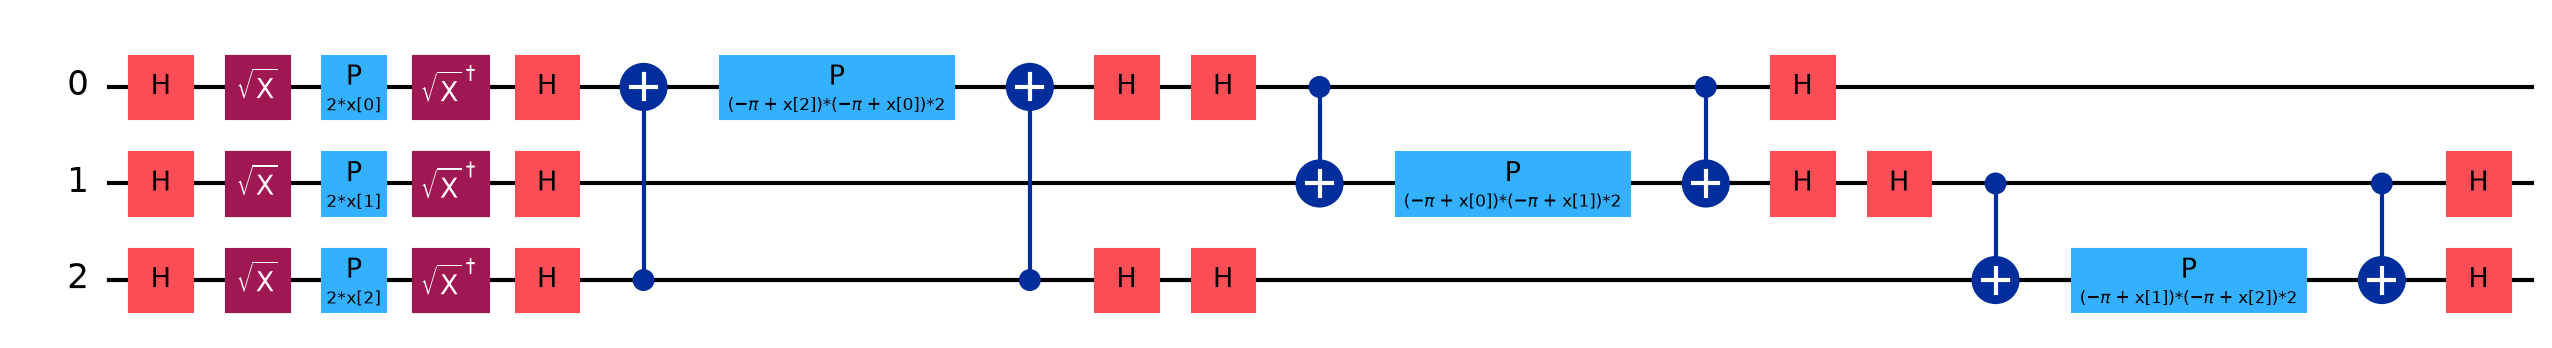

In [11]:
from qiskit.circuit.library import pauli_feature_map
 
feature_dim = 3
pfmap = pauli_feature_map(
    feature_dimension=feature_dim, entanglement='circular', reps=1, paulis=["Y", "XX"]
)
 
pfmap.draw("mpl", scale=1.5)

### efficient_su2

パラメーター化回路を特徴量マップとして使うこともできます。以下は、エンタングルメントを用いたエンコーディングの一般的で便利な例である [`efficient_su2`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.efficient_su2) 回路です。例えばこの回路では、わずか2量子ビットで8個の特徴量をエンコードできます。

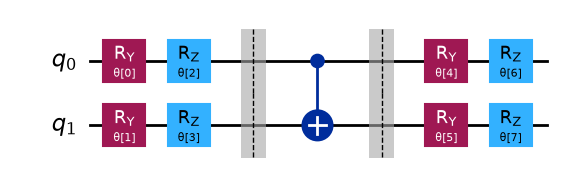

In [12]:
from qiskit.circuit.library import efficient_su2
 
circuit = efficient_su2(num_qubits=2, reps=1, insert_barriers=True)
circuit.draw(output="mpl")

# 2. 量子カーネル分類
## 2.1 カーネル行列の要素
### Step 1: 古典の入力を量子の問題にマッピングする
まず、特徴量がわずか（例えば10個）しかないデータセットを考えましょう。カーネル行列の要素を計算するために少なくとも2つのデータポイントが必要なので、まずそこから始め、必要なパッケージをいくつかインポートします：

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ラベルを含む学習用の2つのデータ点
small_data = [
    [-0.194, 0.114, -0.006, 0.301, -0.359, -0.088, -0.156, 0.342, -0.016, 0.143, 1],
    [-0.1, 0.002, 0.244, 0.127, -0.064, -0.086, 0.072, 0.043, -0.053, 0.02, -1],
]

# 内積計算のためにラベルを除去したデータ点
train_data = [small_data[0][:-1], small_data[1][:-1]]

#### 符号化

このデータを量子特徴量マップを使って量子状態に符号化(エンコード)します。`z_feature_map`を試してみます。

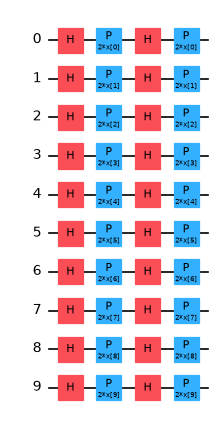

In [14]:
from qiskit.circuit.library import z_feature_map

fm = z_feature_map(feature_dimension=np.shape(train_data)[1])

fm.draw("mpl", scale=0.6)

上記で用意した `train_data` を、ZFeatureMapを使って量子状態にマッピングします。

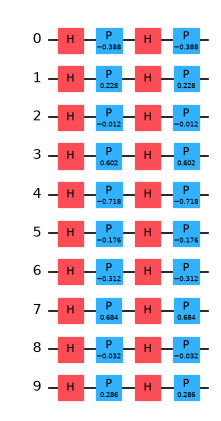

In [15]:
unitary1 = fm.assign_parameters(train_data[0])
unitary2 = fm.assign_parameters(train_data[1])

unitary1.draw("mpl", scale=0.6, fold=-1)

次に、 `unitary_overlap` を使用して量子カーネル行列の1つの要素を計算する量子回路を作成します。また、回路のDepthを確認します。

circuit depth =  9


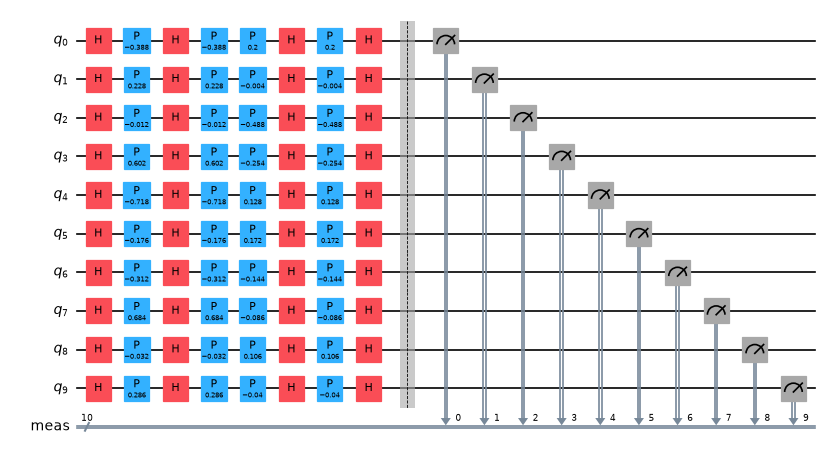

In [16]:
from qiskit.circuit.library import unitary_overlap
overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

print("circuit depth = ", overlap_circ.decompose().depth())
overlap_circ.draw("mpl", scale=0.6, fold=-1)

左半分に学習データ `train_data[0]` 、右半分に学習データ `train_data[1]` がエンコードされています。

### Step 2: 実行のための問題の最適化

AerSimulatorをバックエンドとして使い、上記の回路を最適化します。

In [17]:
# シミュレーターを使います
from qiskit_aer import AerSimulator
backend = AerSimulator()

# 回路を最適化します
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
overlap_ibm = pm.run(overlap_circ)

### Step 3: Qiskit Runtime Primitivesを使って実行する

Qiskit Runtime Primitivesを使って回路を実行します。

In [18]:
# シミュレーターを使います
from qiskit_ibm_runtime.executor_sampler import Sampler
num_shots = 10000
sampler = Sampler(mode=backend)
results = sampler.run([overlap_ibm], shots=num_shots).result()

# .get_counts() は、|001101...01> のようなビットの結果でラベル付けされた状態に対応するカウントを返します。
counts_bit = results[0].data.meas.get_counts()
# .get_int_counts() は同じカウントを返しますが、ラベルは上記のビット列に相当する整数になります。
counts = results[0].data.meas.get_int_counts()

print(counts_bit)

{'0000000000': 6864, '0000000001': 67, '0010000000': 713, '0000010010': 6, '0000010000': 665, '0000001000': 228, '0010010000': 68, '0010000001': 10, '0001010000': 33, '0010001000': 23, '1001000000': 8, '0000000100': 466, '0001000000': 382, '0000010100': 44, '0010000100': 50, '1000000000': 88, '1000001000': 4, '0011000001': 3, '0000001100': 11, '0000000010': 77, '0001000001': 4, '0001000010': 7, '0000010011': 1, '1000010000': 12, '0001001000': 16, '0000011000': 25, '0001000100': 12, '0000000110': 4, '0000001001': 2, '1010000000': 10, '0000001010': 3, '0001011000': 3, '1010001100': 1, '0000011100': 1, '0010001100': 3, '0100000000': 7, '1000000100': 5, '0011000000': 31, '0000010001': 5, '0000000101': 3, '0010000010': 5, '0011000100': 5, '0010011000': 3, '1010000100': 1, '0001010100': 2, '1000000010': 1, '0001001100': 1, '1000001010': 1, '0010010100': 3, '0000000011': 1, '0100000100': 2, '1001001000': 1, '0001010010': 1, '1010010000': 3, '0011011000': 1, '0010000110': 1, '1000010001': 1, '

### Step 4: 後処理を行い、古典の形式で結果を返す

ここで最も有用となる測定は、ゼロの状態 $|0000\rangle$ を測定する確率です。

In [19]:
counts.get(0, 0.0)/num_shots #キー0の値(なければ0.0を返す)

0.6864

カーネル行列の要素の1つをこれで計算できました。ここで参考に実機での実行を行います。

## 2.2 実機実行：カーネル行列の要素

同じ回路をIBM Quantumの実機の量子デバイスを使って実行します。

初めて実機の量子デバイスで実行する場合は、https://github.com/qiskit-community/nedo-seminars-season2/blob/main/20261007/20261007_2_getstarted.ipynb　を参考に、APIキーとCRNを以下のセルに入れて # を外して実行します。

In [20]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# your_api_key = "deleteThisAndPasteYourAPIKeyHere"
# your_crn = "deleteThisAndPasteYourCRNHere"

# service = QiskitRuntimeService.save_account(
#     channel="ibm_cloud",
#     token=your_api_key,
#     instance=your_crn,
#     set_as_default=True,
#     overwrite=True,
#     name = "nedo_q" 
# )

まずデバイスを指定します。

In [21]:
from qiskit_ibm_runtime import QiskitRuntimeService

#service = QiskitRuntimeService()
service = QiskitRuntimeService(name = "nedo_q" )
real_backend = service.least_busy(operational=True)
print("The least busy device is ", real_backend)

The least busy device is  <IBMBackend('ibm_kingston')>


In [ ]:
# 以下でデバイス名を指定することもできます
# backend = service.backend('ibm_pittsburgh')

### Step 2: 実行のための問題の最適化（実機実行）
指定したデバイスに合わせて回路を最適化します。

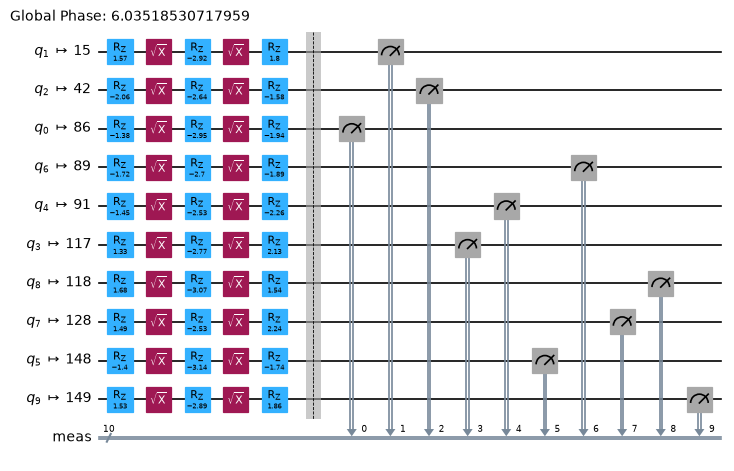

In [22]:
# 回路を最適化します
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
pm = generate_preset_pass_manager(backend=real_backend, optimization_level=3)
overlap_ibm = pm.run(overlap_circ)
overlap_ibm.draw("mpl", scale=0.6, fold=-1)

複雑な回路の場合、実際の量子コンピューターのネイティブゲートへのマッピングが行われ、情報を量子ビット間で移動させる必要が生じることもあるため、このステップで回路の深さが大幅に増加します。今回のような単純なケースでは、深さはほとんど影響を受けません。

In [23]:
print("circuit depth = ", overlap_ibm.depth())
print("two-qubit depth = ", overlap_ibm.depth(filter_function=lambda x: x.operation.num_qubits == 2))

circuit depth =  6
two-qubit depth =  0


### Step 3: Qiskit Runtime Primitivesを使って実行する（実機実行）
Qiskit Runtime Primitivesを使って回路を実行します。ここでは、Samplerのエラー緩和オプションを入れます。エラー緩和については、[Configure noise management with Sampler](https://quantum.cloud.ibm.com/docs/en/guides/sampler-noise-management)、[Error mitigation and suppression techniques](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques) を参照してください。

In [24]:
from qiskit_ibm_runtime.executor_sampler import Sampler
num_shots = 10000
sampler = Sampler(mode=real_backend)

# Samplerのエラー緩和オプションの設定
# シーケンスXpXmを用いて、ダイナミカル・デカップリングを有効にする。
sampler.options.dynamical_decoupling.enable = True
sampler.options.dynamical_decoupling.sequence_type = "XpXm"
# ゲート・トワーリング（gate twirling）を有効にします。qiskit_ibm_runtime 0.23.0以降が必要です。
sampler.options.twirling.enable_gates = True


job_real = sampler.run([overlap_ibm], shots=num_shots)
print("job id:", job_real.job_id())

job id: dbqgtbejjaos73ah9jp0


In [25]:
# Check the job status
job_real.status()

'RUNNING'

In [26]:
# ノートブックセッションが切断された場合は、以下のコードを実行してジョブの状態を確認することもできます。
from qiskit_ibm_runtime import QiskitRuntimeService
#service = QiskitRuntimeService()
service = QiskitRuntimeService(name="nedo_q")
job_real = service.job(job_real.job_id()) # 上の表示されたご自分のjob idを入れ直してください。
#job_real = service.job('dbqgtbejjaos73ah9jp0') # 上の表示されたご自分のjob idを入れ直してください。
job_real.status()

'DONE'

In [27]:
# job statusが 'DONE' になったら
results = job_real.result()
counts_bit = results[0].data.meas.get_counts()
counts = results[0].data.meas.get_int_counts()

print(counts_bit)

{'0000000000': 6795, '0010000000': 708, '0000100000': 45, '0000000001': 69, '0000000100': 462, '0011000000': 31, '0000001000': 241, '0000010000': 636, '0000011000': 31, '0010010000': 52, '0001010000': 34, '0010000100': 40, '0000000010': 86, '0001000000': 341, '1000000000': 114, '0000010100': 42, '1000000100': 12, '0001010100': 4, '0000010001': 8, '0001000001': 4, '0010001000': 20, '0010000001': 6, '0000001100': 24, '1000100100': 1, '0100100000': 1, '0010001100': 2, '0010000101': 1, '0000100100': 5, '0100000000': 16, '0001100000': 4, '0000010010': 8, '0000011010': 1, '0001001000': 10, '0010100100': 1, '0001000100': 21, '0000100001': 1, '0010010001': 2, '0101000010': 1, '0001000010': 7, '0011010000': 6, '1001000000': 7, '0011001100': 1, '1010000000': 13, '0010011000': 4, '0000000110': 3, '0000001001': 3, '1000010000': 12, '0010001001': 2, '0000110000': 4, '0011000100': 1, '0000000101': 3, '1010001000': 1, '0010100000': 5, '0001000110': 2, '0110000000': 2, '0010010100': 9, '0010000010': 1

### Step 4: 後処理を行い、古典の形式で結果を返す（実機実行）
ゼロの状態 $|0000\rangle$ を測定する確率を計算します。

In [28]:
counts.get(0, 0.0)/num_shots

0.6795

カーネル行列の要素の1つをこれで計算できました。すなわち、2つのデータ点に対応するベクトルの内積（の絶対値の2乗）の推定値です。測定確率（または準確率）の分布全体を見たい場合は、以下に示すように `plot_distribution` 関数を使うことができます。量子ビット数が多くなると、このような図はすぐに扱いきれなくなることがわかります。

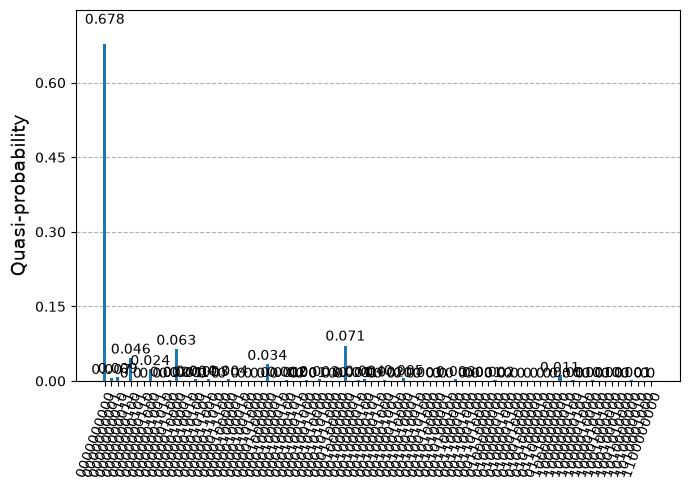

In [29]:
from qiskit.visualization import plot_distribution
plot_distribution(counts_bit)

あるいは、以下のように確率の高い上位10個の測定結果だけを見ることもできます。これはトラブルシューティングや、データについての直感を得るために重要になる場合があります。ただし、カーネル行列の要素はあくまでゼロ状態の測定確率です。

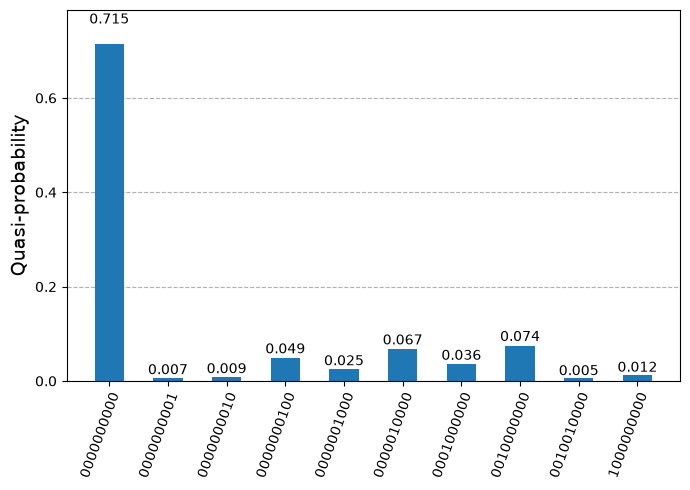

In [30]:
top10 = dict(sorted(counts_bit.items(), key=lambda x: x[1], reverse=True)[:10])
plot_distribution(top10)

高次元の特徴量空間における2つのデータ点間の内積1つだけの情報からは、両者の重なりが大きめである（最大の重なりは 1.0 ）ということしか言えません。これは、この2つのデータ点が何らかの意味で性質が似ており、同じクラスに分類されることを示しているのかもしれません。あるいは、似たデータどうしの重なりが大きく、似ていないデータどうしの重なりが小さくなるような空間へのマッピングとして、特徴量マップが効果的でないことを示しているのかもしれません。どちらが正しいかを知るには、特徴量マップをデータ全体に適用し、得られたカーネル行列を使って高い精度でクラスを効果的に分離できるかどうかを確かめる必要があります。



ここでは `z_feature_map` を使ったため、トランスパイル後の2量子ビット深さが小さく（実際には深さ0）なったことは注目に値します。回路が深くなりすぎると、必ず多くのノイズが生じ、たとえ特徴量マップがデータによく適合していても、ゼロ状態を測定する確率は非常に低くなってしまいます。

例えば、同じデータ点に対して `zz_feature_map` と `, entanglement='linear', reps=1` を使って上記の処理を繰り返したところ、`dist.get(0,0.0) = 0.0015` という結果になりました。これは、`zz_feature_map` の回路の深さと2量子ビット深さがはるかに大きいためです。

circuit depth =  54
two-qubit depth =  34


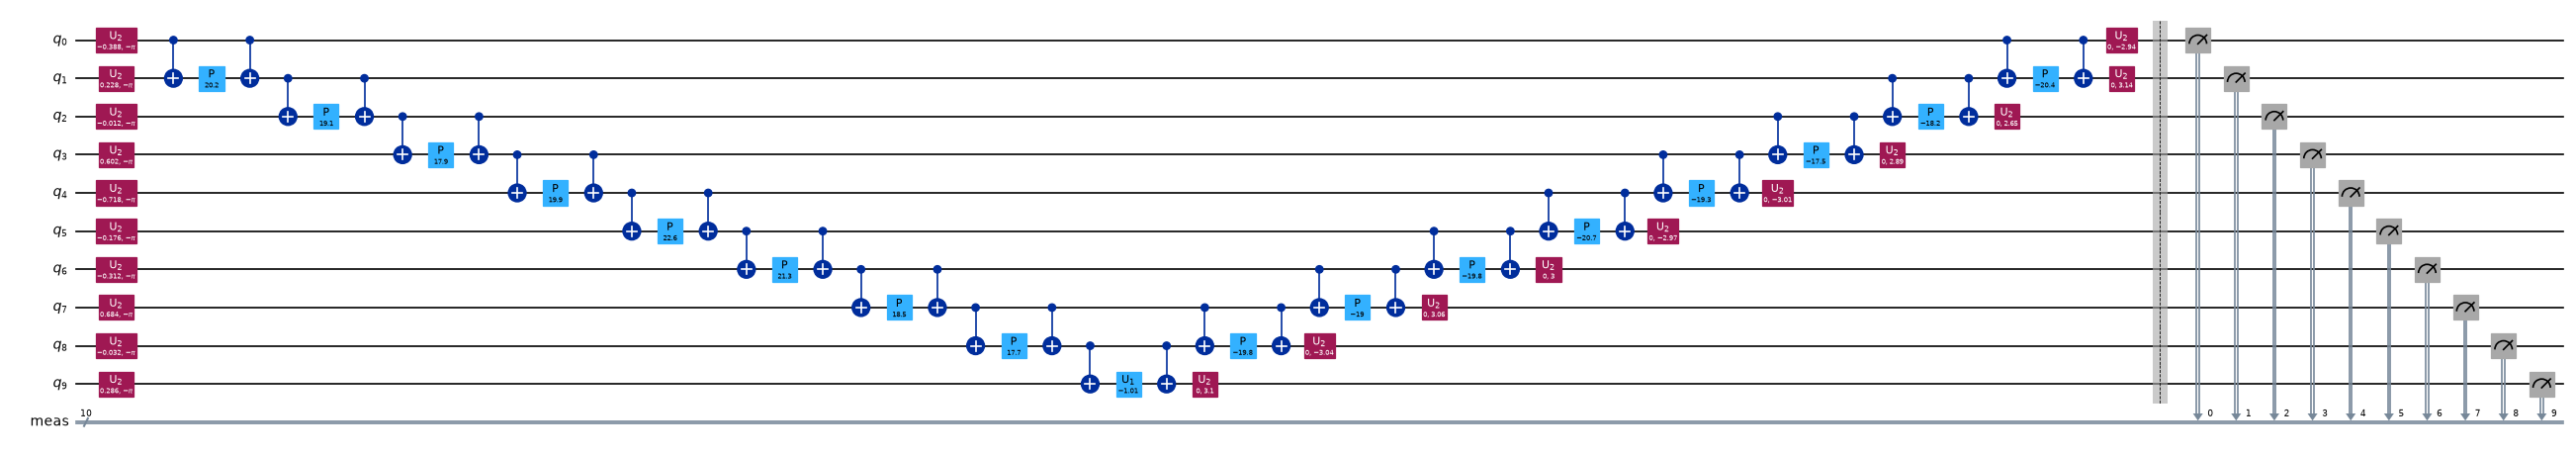

In [31]:
from qiskit.circuit.library import zz_feature_map

zz_fm = zz_feature_map(feature_dimension=np.shape(train_data)[1], entanglement='linear', reps=1)

unitary1 = zz_fm.assign_parameters(train_data[0])
unitary2 = zz_fm.assign_parameters(train_data[1])

overlap_circ_zz = unitary_overlap(unitary1, unitary2)
overlap_circ_zz.measure_all()

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
overlap_ibm_zz = pm.run(overlap_circ_zz)

print("circuit depth = ", overlap_ibm_zz.depth())
print("two-qubit depth = ", overlap_ibm_zz.depth(filter_function=lambda x: x.operation.num_qubits == 2) )
overlap_ibm_zz.draw("mpl", scale=0.6, fold=-1)

In [32]:
print("circuit depth = ", overlap_ibm_zz.depth())
print("two-qubit depth = ", overlap_ibm_zz.depth(filter_function=lambda x: x.operation.num_qubits == 2))

circuit depth =  54
two-qubit depth =  34


同じカテゴリーに属するデータを使って、良い結果を得るために深さをどの程度まで小さくする必要があるかを調べてみる価値があります。

一般に、トランスパイル後の2量子ビット深さが10以下であれば問題はないはずです。トランスパイル後の2量子ビット深さが50〜60であれば最先端の水準であり、高度なエラー緩和をはじめとするさまざまなツールが必要になります。その間くらいの深さの場合、データの類似度、特徴量マップの表現力、回路の幅などの要因によって結果が変わる可能性があります。

## 2.3 完全なカーネル行列

このセクションでは、上記のプロセスを完全なデータセットの2値分類に拡張します。ここでの特徴量マップは、Qiskitの組み込みfeature mapを使わずに、自作します。完全なカーネル行列を作ったあと、古典の機械学習を実装し、学習精度のスコアを求めます。

### Step 1: 古典の入力を量子の問題にマッピングする
ここで、分類のために既存のデータセットをインポートします。このデータセットは128行（データポイント）と各ポイントにおける14個の特徴量からなります。また、各ポイントにはバイナリーのカテゴリー ($\pm 1$) を示す15番目の要素があります。データセットは以下でインポートされます。また、[ここ](https://github.com/qiskit-community/prototype-quantum-kernel-training/blob/main/data/dataset_graph7.csv)からデータセットにアクセスしてその構造を見ることもできます。

128のデータポイントのうち、最初の60データポイントを学習に使い、次の20ポイントをテストに使います。

In [24]:
!wget https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv

df = pd.read_csv("dataset_graph7.csv", sep=",", header=None)

# 学習データの準備
train_size = 60
X_train=df.values[0:train_size,:-1]
train_labels = df.values[0:train_size,-1]

# テストデータの準備
test_size = 20
X_test=df.values[train_size:train_size+test_size,:-1]
test_labels=df.values[train_size:train_size+test_size,-1]

--2026-11-09 09:03:59--  https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv
raw.githubusercontent.com (raw.githubusercontent.com) をDNSに問いあわせています... 2606:50c0:8000::154, 2606:50c0:8001::154, 2606:50c0:8002::154, ...
raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443 に接続しています... 接続しました。
HTTP による接続要求を送信しました、応答を待っています... 200 OK
長さ: 49405 (48K) [text/plain]
`dataset_graph7.csv.7' に保存中

dataset_graph7.csv. 100%[===================>]  48.25K   219KB/s 時間 0.2s       

2026-11-09 09:04:00 (219 KB/s) - `dataset_graph7.csv.7' へ保存完了 [49405/49405]



出力を格納するために、空のカーネル行列と、適切な次元の空のテスト用カーネル行列を作ります。

In [25]:
# 空のカーネル行列
num_samples = np.shape(X_train)[0]
kernel_matrix = np.full((num_samples, num_samples), np.nan) # 60x60の学習用カーネル行列
test_matrix = np.full((test_size, num_samples), np.nan) # 20x60のテスト用カーネル行列

次に、古典データを量子回路に符号化するための特徴量マップを自作します。

In [26]:
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit

# overlapを計算するための特徴量の準備
num_features = np.shape(X_train)[1] #14
num_qubits = int(num_features / 2) #7

# カスタムのfeature mapでは、以下の行をエンタングルメントさせます
entangler_map = [[0, 2], [3, 4], [2, 5], [1, 4], [2, 3], [4, 6]]

fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits) # pi/2回転なのでHゲートと等価
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)

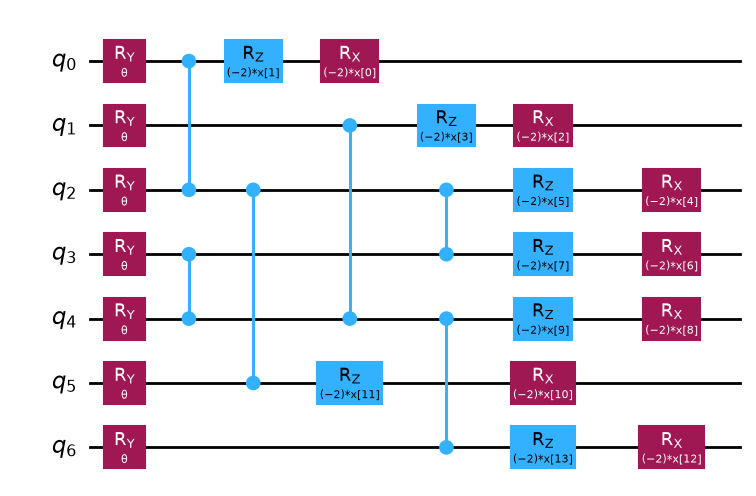

In [27]:
fm.draw("mpl") # 各qubitに2つのデータをエンコードするため7qubit回路

### Step 2 & 3: 問題を最適化し、primitiveを使って実行する

Overlap回路を作ります。カーネル行列は対角に対して対称なので、同じ計算は繰り返さないようにすることで、計算回数は二分の一に減らせます。また、ノイズがない場合は対角要素が1となるため、今回は対角要素を計算せず、1を代入します。(60×60×1/2-60)要素と(20×60)要素の合計2920要素を計算するので、以下のセルは実行にすこし時間がかかります。

In [28]:
num_shots = 1000

backend = AerSimulator()
sampler = Sampler(mode=backend)

for x1 in range(0,train_size):
    for x2 in range(x1+1,train_size):
        unitary1 = fm.assign_parameters(list(X_train[x1]) + [np.pi / 2]) #パラメーターは名前のアルファベット順に並ぶ
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2]) #今回は x の次に θ

        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()
    
        # Qiskit sampler primitiveの実行
        counts = (
            sampler.run([overlap_circ], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

        # |0>状態の確率をカーネル行列の要素に入れ、転置された要素にも同じ確率を入れます。
        kernel_matrix[x1, x2] = counts.get(0, 0.0)/num_shots
        kernel_matrix[x2, x1] = counts.get(0, 0.0)/num_shots
    # 確率の内積なので、対角線上の要素を1で埋めます
    kernel_matrix[x1,x1] =1    

print("training done")

# 上記と同様のプロセスをテストデータを使って行う
for x1 in range(0,test_size):
    for x2 in range(0,train_size):
        unitary1 = fm.assign_parameters(list(X_test[x1]) + [np.pi / 2])
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2])

        # Overlap回路の作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()
    
        counts = (
            sampler.run([overlap_circ], shots=num_shots).result()[0].data.meas.get_int_counts()
        )

        test_matrix[x1, x2] = counts.get(0, 0.0)/num_shots

print("test matrix done")

training done
test matrix done


2つのカーネル行列を見てみましょう。

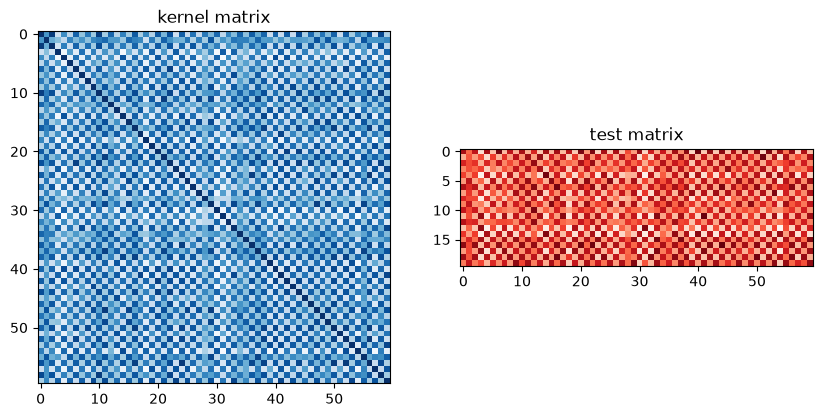

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(np.asmatrix(kernel_matrix),
              interpolation='nearest', origin='upper', cmap='Blues')
axs[0].set_title("kernel matrix")
axs[1].imshow(np.asmatrix(test_matrix),
              interpolation='nearest', origin='upper', cmap='Reds')
axs[1].set_title("test matrix")
plt.show()

### Step 4: 後処理を行い、古典の形式で結果を返す

量子カーネル法からカーネル行列と同様の形式の test_matrix が得られたので、古典の機械学習アルゴリズムを適用してテストデータの予測を行い、その精度をチェックすることができます。まず、Scikit-Learnの`sklearn.svc`、サポートベクトル分類器（SVC）をインポートします。SVC に事前に計算したカーネルを使わせたい場合は、`kernel = precomputed` を使って指定します。

In [30]:
# 古典の機械学習パッケージからサポートベクトル分類器をインポート
from sklearn.svm import SVC

# 事前に計算されたカーネル行列を使用することを指定
qml_svc = SVC(kernel="precomputed")

`SVC.fit` を使って、カーネル行列と学習用ラベルを入力し、fitを得ることができます。`SVC.predict` は test_matrix を使ってテストデータのラベルを予測します。`SVC.score` はテストデータをスコアリングして精度を返します。

In [31]:
# 事前に計算された行列と学習データのラベルを入力。古典アルゴリズムがfitを行います。
qml_svc.fit(kernel_matrix, train_labels)

# 学習データとテストデータのカーネル行列を用いてテストデータのラベルを予測します。
label_predict = qml_svc.predict(test_matrix)
print(label_predict, test_labels, sep="\n")

# テストデータの行列とテストラベルを入力として、.scoreを使ってデータをテストします。
qml_score_precomputed_kernel = qml_svc.score(test_matrix, test_labels)
print(f"Precomputed kernel classification test score: {qml_score_precomputed_kernel}")

[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.
  1. -1.]
[ 1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.  1. -1.
  1. -1.]
Precomputed kernel classification test score: 1.0


学習したモデルの精度は100%でした。これは素晴らしいことで、QKE(Quantum Kernel Estimation)が機能することを示しています。しかし、これは量子の優位性ではありません。古典カーネルでも、おそらくこの分類問題を100%の精度で解くことができるでしょう。現在のユーティリティ時代に量子カーネルが最も役立つのはどこなのか、さまざまなデータタイプやデータ関係を特徴づけるためにやるべきことはたくさんあります。量子特徴量マップを変更してその有効性を研究してみてください。

## 2.4 より多くの特徴量と量子ビットへのスケーリング

特徴量の数を多くし、ユーティリティーに向けてスケールアップする道筋を紹介します。量子コンピューターの計算時間削減のため、ここでは行列要素1つのみの計算に限定します。

### ステップ1: 古典的な入力を量子問題にマッピングする

各データ点が42個の特徴量を持つデータセットを出発点とします。カーネル行列の要素を1つ計算するので、2つのデータ点が必要です。以下の2つの点は、42個の特徴量と1つのカテゴリー変数（$\pm 1$）を持っています。

In [33]:
# 学習データとカテゴリーラベルを含む2つの模擬データ点

large_data = [
    [
        -0.028,
        -1.49,
        -1.698,
        0.107,
        -1.536,
        -1.538,
        -1.356,
        -1.514,
        -0.109,
        -1.8,
        -0.122,
        -1.651,
        -1.955,
        -0.123,
        -1.732,
        0.091,
        -0.048,
        -0.128,
        -0.026,
        0.082,
        -1.263,
        0.065,
        0.004,
        -0.055,
        -0.08,
        -0.173,
        -1.734,
        -0.39,
        -1.451,
        0.078,
        -1.578,
        -0.025,
        -0.184,
        -0.119,
        -1.336,
        0.055,
        -0.204,
        -1.578,
        0.132,
        -0.121,
        -1.599,
        -0.187,
        -1,
    ],
    [
        -1.414,
        -1.439,
        -1.606,
        0.246,
        -1.673,
        0.002,
        -1.317,
        -1.262,
        -0.178,
        -1.814,
        0.013,
        -1.619,
        -1.86,
        -0.25,
        -0.212,
        -0.214,
        -0.033,
        0.071,
        -0.11,
        -1.607,
        0.441,
        -0.143,
        -0.009,
        -1.655,
        -1.579,
        0.381,
        -1.86,
        -0.079,
        -0.088,
        -0.058,
        -1.481,
        -0.064,
        -0.065,
        -1.507,
        0.177,
        -0.131,
        -0.153,
        0.07,
        -1.627,
        0.593,
        -1.547,
        -0.16,
        -1,
    ],
]
train_data = [large_data[0][:-1], large_data[1][:-1]]

2.2章の例で、`zz_feature_map` は、特徴量が比較的少ない場合（14個の特徴量）でもかなり深い回路になりました。特徴量の数を増やすにつれて、回路の深さを注意深くみていく必要があります。これを示すために、まず `zz_feature_map` を使ってみて、得られる回路の深さを確認します。

In [34]:
from qiskit.circuit.library import zz_feature_map

fm = zz_feature_map(feature_dimension=np.shape(train_data)[1], entanglement="linear", reps=1)

unitary1 = fm.assign_parameters(train_data[0])
unitary2 = fm.assign_parameters(train_data[1])

In [35]:
from qiskit.circuit.library import unitary_overlap

overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()
overlap_circ.draw("mpl", fold=-1)

In [36]:
print("circuit depth = ", overlap_circ.depth())
print("two-qubit depth",overlap_circ.depth(filter_function=lambda x: x.operation.num_qubits == 2))

circuit depth =  251
two-qubit depth 164


どの程度の深さなら深すぎるのかを正確に判断するのは微妙な問題です。しかし、トランスパイル前の時点ですでに2量子ビット深さが100を超えているようでは、まったく話になりません。

データセット全体の構造について何らかの知見があるなら、その構造を念頭に置いてエンタングルメント・マップを設計すべきです。ここでは、データ点2つの間の内積を計算するだけなので、データ構造の詳細な検討よりも回路の深さを小さくすることを優先します。

In [37]:
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit

# overlap計算用の特徴量マップを準備
entangler_map = [
    [3, 4],
    [2, 5],
    [1, 4],
    [2, 3],
    [4, 6],
    [7, 9],
    [10, 11],
    [9, 12],
    [8, 11],
    [9, 10],
    [11, 13],
    [14, 16],
    [17, 18],
    [16, 19],
    [15, 18],
    [16, 17],
    [18, 20],
]

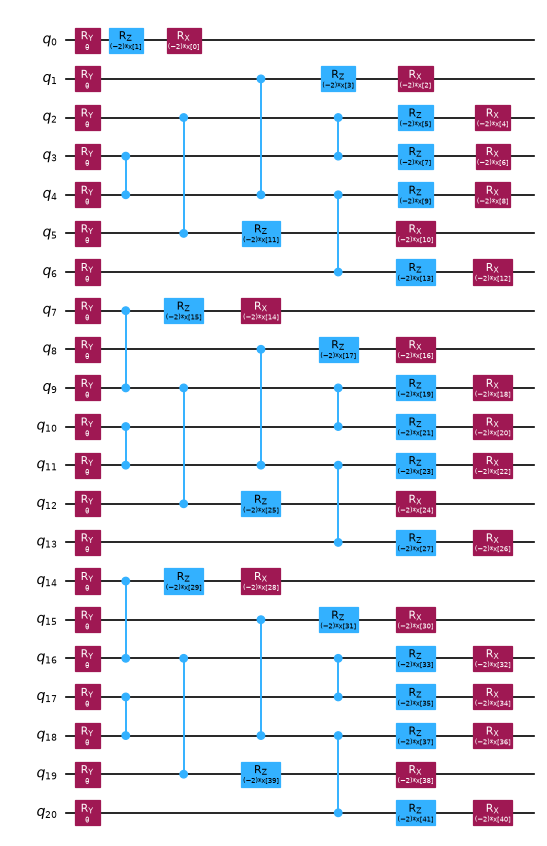

In [38]:
# 上のEntangler mapを使って特徴量マップを構築

num_features = np.shape(train_data)[1]
num_qubits = int(num_features / 2)

fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits)
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)
fm.draw("mpl", scale=0.6)

In [39]:
from qiskit.circuit.library import unitary_overlap

# 各データ点の特徴量を、一般的な特徴量マップのインスタンスであるユニタリーに割り当てます。
unitary1 = fm.assign_parameters(list(train_data[0]) + [np.pi / 2])
unitary2 = fm.assign_parameters(list(train_data[1]) + [np.pi / 2])

# オーバーラップ回路を作成
overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

重要なのはトランスパイル後の2量子ビット深さなので、ここではまだ深さを確認しません。

### ステップ2: 量子実行向けに問題を最適化する

まず最も空いているバックエンドを選択し、そのバックエンドで実行できるように回路を最適化します。

In [40]:
# 必要なパッケージをインポート
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService

# 最も空いているバックエンドを取得
#service = QiskitRuntimeService()
service = QiskitRuntimeService(name="nedo_q")
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=fm.num_qubits)
print(backend)

<IBMBackend('ibm_marrakesh')>


小規模なジョブでは、preset_passmanagersは多くの場合、同じ深さの同じ回路を確実に返します。しかし、非常に大規模で複雑な回路では、passmanagerは実行するたびに異なるトランスパイル済み回路を返すことがあります。これは、passmanagerがヒューリスティクスを用いており、また非常に大規模な回路では可能な最適化の地形が複雑になるためです。何回かトランスパイルを行い、最も浅い回路を採用すると役立つことがよくあります。これによって生じるのは古典的なオーバーヘッドのみであり、量子コンピューターから得られる結果が大幅に改善される可能性があります。

ここでは、ユニタリー・オーバーラップ回路を20回トランスパイルし、得られた回路の深さを確認します。

In [41]:
# オーバーラップ回路にレベル3の最適化を適用
transpiled_qcs = []
transpiled_depths = []
transpiled_twoqubit_depths = []
for i in range(1, 20):
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=42)
    overlap_ibm = pm.run(overlap_circ)
    transpiled_qcs.append(overlap_ibm)
    transpiled_depths.append(overlap_ibm.depth())
    transpiled_twoqubit_depths.append(
        overlap_circ.depth(filter_function=lambda x: x.operation.num_qubits == 2)
    )

print(transpiled_depths)
print(transpiled_twoqubit_depths)

[20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]
[6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6]


この回路はまだ、トランスパイル後の深さにばらつきが見られるほど深く/幅広くはありませんでした。ここでは `transpiled_qcs[0]` を使います。

In [42]:
overlap_ibm = transpiled_qcs[0]

### ステップ3: IBM Quantum primitives を使って実行する

ユーティリティー規模に近づくにつれて、シミュレーターは役に立たなくなります。ここでは、実際の量子コンピューター向けの構文のみを示します

In [43]:
from qiskit_ibm_runtime import Session
from qiskit_ibm_runtime.executor_sampler import Sampler

# セッションを開く:
session = Session(backend=backend)
num_shots = 10000
# Sampler を使ってカウントを取得

sampler = Sampler(mode=session)

# Samplerのエラー緩和オプションの設定
options = sampler.options
options.dynamical_decoupling.enable = True
options.twirling.enable_gates = True

job = sampler.run([overlap_ibm], shots=num_shots)
print("job id:", job.job_id())

# 完了後にセッションを閉じる
session.close()

job id: dbogtjlt7fqc7387re10


In [45]:
# Check the job status
job.status()

'DONE'

### ステップ4: 後処理を行い、結果を古典的な形式で返す

ここで最も有用な測定値はゼロ状態 $|00000\rangle$ を測定する確率です。

In [46]:
# job statusが 'DONE' になったら
results = job.result()
counts = results[0].data.meas.get_int_counts()
counts.get(0, 0.0) / num_shots

0.0061

この単一のカーネル行列要素を求める処理を、データセット内の他のすべてのデータペアについて繰り返して計算することで、カーネル行列全体が得られます。

特徴量マップを自作する例として、今回はデータの特性がわかっている場合について、相関のある特徴量同士をエンタングルメントでつなぎ、回路深さを削減する手法を紹介しました。この例を含め、アイディアとして以下のような例が報告されています。
- 相関のある特徴量どうしを、エンタングルメントでつなぐ([Covariant quantum kernels for data with group structure](https://arxiv.org/abs/2105.03406))
- 特徴量のスケール(回転角に掛ける係数)を調整する([Importance of kernel bandwidth in quantum machine learning](https://link.aps.org/doi/10.1103/PhysRevA.106.042407)、[Bandwidth enables generalization in quantum kernel models](https://arxiv.org/abs/2206.06686))
- 深さ・エンタングルメントを増やしすぎない([Exponential concentration in quantum kernel methods](https://www.nature.com/articles/s41467-024-49287-w))
- カーネル・アラインメントで理想的なカーネルと比較して、特徴量マップの評価を簡単に行う([Training quantum embedding kernels on near-term quantum computers](https://link.aps.org/doi/10.1103/PhysRevA.106.042431))

また、符号化した回路からパウリ行列の期待値を射影測定で求め、そのベクトル同士の距離をガウスカーネルで求める射影量子カーネル(PQK)という手法も知られており、[こちらのチュートリアル](https://quantum.cloud.ibm.com/docs/en/tutorials/projected-quantum-kernels)では、実際の生物データセットに対してPQKによる分類を実装しています。

# 3. 量子変分回路による分類

このチュートリアルでは、`Estimator` による量子ニューラルネットワーク(QNN)を使った分類を紹介します。以下の手順に従います。

1. 特徴量マップとアンザッツを合成して回路を作る
2. `forward` 関数でプリミティブ(`Estimator`)を実行して QNN の出力を得る
3. 損失関数とコスト関数を定義し、`scipy.optimize.minimize` で重みを最適化する
4. `sklearn.metrics` で性能を評価する

## 3.1 データの準備

まず、簡単な分類用データセットを用意します。$-1$以上$+1$未満の範囲にあるランダムな20個のデータ $X=(x_0,x_1)$ が $x_1=-x_0$ の境界線で分類されているデータです。$x_1=-x_0$より上に位置するデータは$y=+1$(青丸)、下に位置するデータは$y=-1$(緑丸)にラベル付けされます。

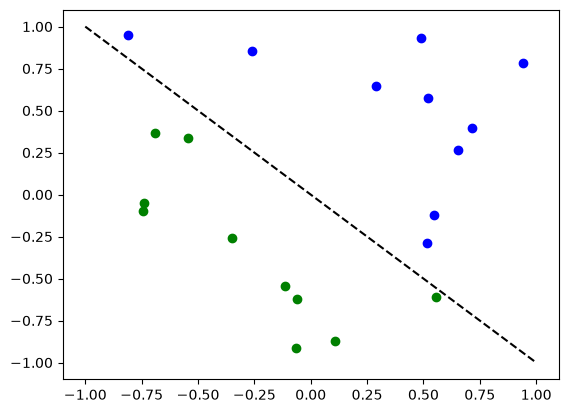

In [47]:
seed = 42
rng = np.random.default_rng(seed)

num_inputs = 2
num_samples = 20
X = 2 * rng.random([num_samples, num_inputs]) - 1 # [-1, 1)の2次元の乱数
y01 = 1 * (np.sum(X, axis=1) >= 0)  # { 0,  1}のラベル付け
y = 2 * y01 - 1  # {-1, +1} にラベルを変換

for x, y_target in zip(X, y):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

In [48]:
# 例
print(X[0], y[0])

[ 0.5479121  -0.12224312] 1


## 3.2 `Estimator` を使った QNN による分類

オブザーバブルの期待値を QNN の出力とする分類を行います。オブザーバブルを $Z^{\otimes n}$ とすると出力は $[-1, +1]$ の範囲になるので、2値分類のクラスを出力が$0$以上なら$+1$、$0$未満なら$-1$のように$\{-1, +1\}$ に割り当て、出力の符号で予測します。

特徴量マップ(データのエンコード)に `zz_feature_map`、アンザッツ(学習するパラメーターを持つ回路)に `real_amplitudes` を使い、2つを合成して1つの回路にします。

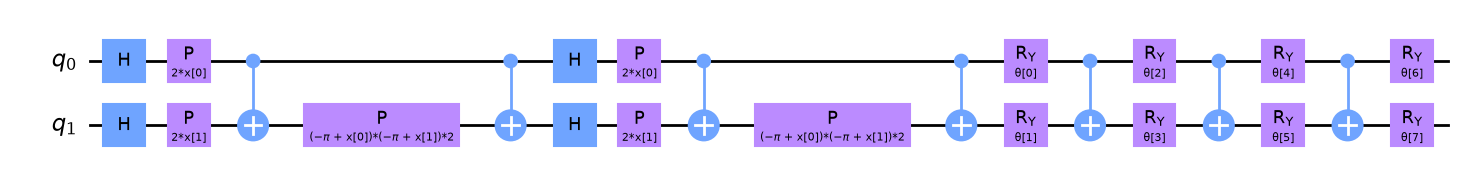

In [49]:
from qiskit.circuit.library import real_amplitudes, zz_feature_map

# データのエンコード(特徴量マップ)
feature_map = zz_feature_map(num_inputs)

# QNN のアンザッツ
ansatz = real_amplitudes(num_inputs)

# 特徴量マップとアンザッツを合成
full_circuit = QuantumCircuit(num_inputs)
full_circuit.compose(feature_map, range(num_inputs), inplace=True) #元の回路に追加
full_circuit.compose(ansatz, range(num_inputs), inplace=True)

full_circuit.draw("mpl", style="clifford")

プリミティブはパラメーターの値が `circuit.parameters` の順序で渡されます。ここで確認してみます。Qiskit はパラメーターを名前のアルファベット順に並べるので、
特徴量マップのパラメーター `x[0], x[1]` がアンザッツのパラメーター `θ[0], ..., θ[7]` より先に来ます。
そのため、以下の `forward` 関数では「入力データ → 重み」の順にパラメーターを連結します。

In [50]:
print(full_circuit.parameters)
print(f"入力パラメーター数: {feature_map.num_parameters}, 重みパラメーター数: {ansatz.num_parameters}")

ParameterView([ParameterVectorElement(x[0]), ParameterVectorElement(x[1]), ParameterVectorElement(θ[0]), ParameterVectorElement(θ[1]), ParameterVectorElement(θ[2]), ParameterVectorElement(θ[3]), ParameterVectorElement(θ[4]), ParameterVectorElement(θ[5]), ParameterVectorElement(θ[6]), ParameterVectorElement(θ[7])])
入力パラメータ数: 2, 重みパラメータ数: 8


測定するオブザーバブルとして、すべての量子ビットの $Z$ のテンソル積を定義します。

In [51]:
from qiskit.quantum_info import SparsePauliOp
observable = SparsePauliOp.from_list([("Z" * num_inputs, 1)])
print(observable)

SparsePauliOp(['ZZ'],
              coeffs=[1.+0.j])


QNN の順伝播(forward pass)を定義します。すべてのデータ点のパラメーターをまとめた配列を1つの PUB としてプリミティブに渡すので、
1回の `estimator.run` で20サンプル全ての期待値が得られます。今回は実機ではなく、状態ベクトルシミュレーションを行うので、
`estimator` には `qiskit.primitives.StatevectorEstimator` を使います。

In [52]:
def forward(circuit, input_params, weight_params, estimator, observable):
    """
    ニューラルネットワークの順伝播。

    circuit: 特徴量マップとアンザッツからなる回路。
    input_params: データのエンコードに使うパラメーター。形状は (サンプル数, 入力パラメーター数)。
    weight_params: アンザッツのパラメーター(重み)。
    estimator: Estimator プリミティブ。
    observable: 期待値を計算するオブザーバブル。

    output: 各サンプルの期待値の配列。
    """
    num_samples = input_params.shape[0]
    weights = np.broadcast_to(weight_params, (num_samples, len(weight_params)))
    params = np.concatenate((input_params, weights), axis=1)
    pub = (circuit, observable, params)
    job = estimator.run([pub])
    result = job.result()[0]
    expectation_values = result.data.evs

    return expectation_values

ランダムな重みパラメーターをansatzに入れて、一つ目のデータを渡してみます。出力は $[-1, +1]$ の範囲になります。

In [53]:
from qiskit.primitives import StatevectorEstimator as Estimator
estimator = Estimator()

# QNN は入力を [-1, +1] に写す。ランダムなパラメーターをansatzに入れて、一つ目のデータを渡してみます
forward(full_circuit, X[:1], rng.random(ansatz.num_parameters), estimator, observable)

array([0.23521988])

損失関数として平均二乗誤差(MSE)を使います。

In [54]:
def mse_loss(predict, target):
    """
    平均二乗誤差(MSE)。

    predict: ニューラルネットワークの順伝播による予測。
    target: 正解ラベル。

    output: MSE 損失。
    """
    return ((predict - target) ** 2).mean()

オプティマイザーが最小化するコスト関数を定義します。コスト関数は重みだけを引数に取り、回路やデータはグローバル変数
(`circuit`, `input_params`, `target`, `estimator`, `observable`)を参照します。
各評価での損失の値を `objective_func_vals` に記録し、学習後に反復回数と目的関数値の関係をプロットします。

In [55]:
def mse_loss_weights(weight_params):
    """
    アンザッツのパラメーターを更新するためのコスト関数。

    weight_params: オプティマイザが更新するアンザッツのパラメーター。

    output: MSE 損失。
    """
    predictions = forward(
        circuit=circuit,
        input_params=input_params,
        weight_params=weight_params,
        estimator=estimator,
        observable=observable,
    )

    cost = mse_loss(predict=predictions, target=target) # QNN の出力が、理想の値 ±1 にどれだけ近いか
    objective_func_vals.append(cost) # 損失の値を objective_func_vals に記録

    global iteration
    if iteration % 10 == 0: # 10回ごとに損失(平均二乗誤差)を表示します
        print(f"Iter: {iteration}, loss: {cost}")
    iteration += 1

    return cost


def plot_objective(objective_func_vals):
    plt.figure(figsize=(12, 6))
    plt.title("Objective function value against iteration")
    plt.xlabel("Iteration")
    plt.ylabel("Objective function value")
    plt.plot(range(len(objective_func_vals)), objective_func_vals)
    plt.show()

グローバル変数を設定し、COBYLA オプティマイザーで最大60回の反復を行って重みを学習します。重みの初期値は $[0, 1)$ の一様乱数です。

Iter: 0, loss: 1.2937952432256885
Iter: 10, loss: 0.9453567618411904
Iter: 20, loss: 1.194155463254782
Iter: 30, loss: 0.8172643165962213
Iter: 40, loss: 0.7694430253054643
Iter: 50, loss: 0.7461386449112075


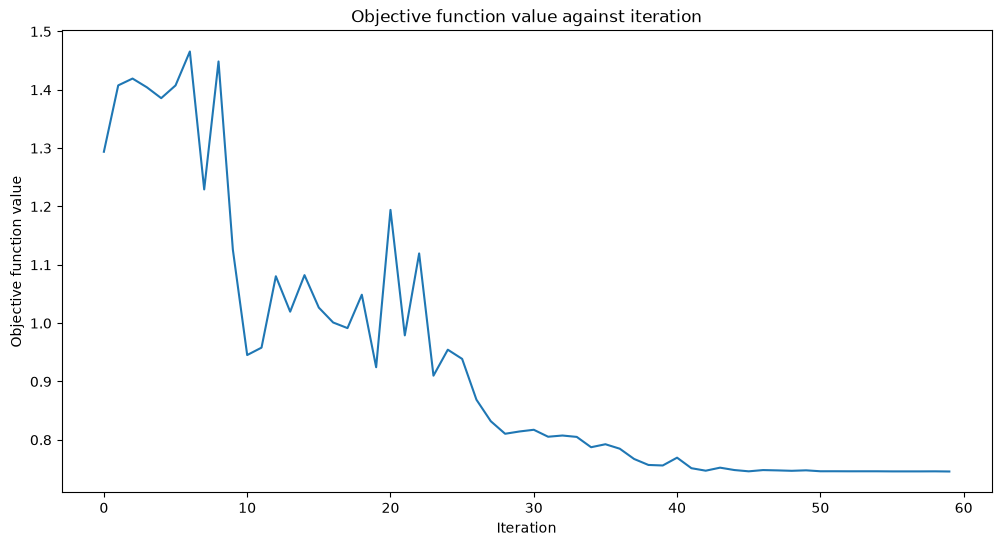

In [56]:
from scipy.optimize import minimize

# グローバル変数
circuit = full_circuit
input_params = X
target = y
objective_func_vals = []
iteration = 0

# アンザッツの重みの初期値
weight_params = rng.random(ansatz.num_parameters)

res = minimize(mse_loss_weights, weight_params, method="COBYLA", options={"maxiter": 60})
plot_objective(objective_func_vals)

学習した重み `res.x` を使って予測します。期待値が 0 以上なら $+1$、0 未満なら $-1$ と予測し、正解率を計算します。

In [57]:
from sklearn.metrics import accuracy_score

pred = forward(circuit, X, res.x, estimator, observable) # 学習された重みによる期待値
y_predict = np.where(pred >= 0, 1, -1) # クラス分類の予測

accuracy = accuracy_score(y, y_predict) # 学習精度
print(f"Train accuracy: {accuracy * 100}%")

Train accuracy: 80.0%


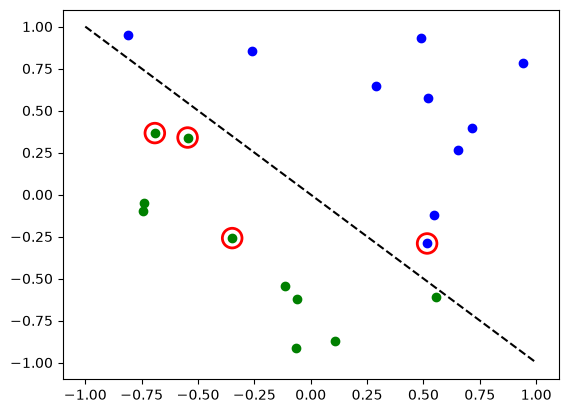

In [58]:
# 結果をプロット
# 赤丸 = 誤分類
for x, y_target, y_p in zip(X, y, y_predict):
    if y_target == 1:
        plt.plot(x[0], x[1], "bo")
    else:
        plt.plot(x[0], x[1], "go")
    if y_target != y_p:
        plt.scatter(x[0], x[1], s=200, facecolors="none", edgecolors="r", linewidths=2)
plt.plot([-1, 1], [1, -1], "--", color="black")
plt.show()

学習済みの重みは次のとおりです。重みの数はアンザッツによって決まります。

In [59]:
res.x

array([ 0.89746992, -0.58919861, -0.2969508 , -0.48951879,  1.09632434,
        0.1428484 ,  2.43383222, -0.9981628 ])

今回はEstimatorを使ったQNNによる量子変分回路分類を紹介しました。

その他、SamplerをつかったQNN分類や回帰学習などもあります。https://stfc.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html にはこれらの関数がライブラリーにまとまっています。

参照：
- [IBM Quantum Learning Course "Quantum machine learning"](https://quantum.cloud.ibm.com/learning/en/courses/quantum-machine-learning)／[和訳](https://quantum-tokyo.github.io/introduction/courses/quantum-machine-learning/quantum-machine-learning_ja.html)
- [Qiskit Machine Learning v0.9.1](https://stfc.github.io/qiskit-machine-learning/)／[和訳 v0.7.1](https://stfc.github.io/qiskit-machine-learning/locale/ja_JP/index.html)

© IBM Corp., 2026